# 03 — Champion vs Challengers: XGBoost and LightGBM

**Goal:** Use the **same feature list, saved train/validation split, and evaluation metrics** as Notebook 2 to benchmark XGBoost and LightGBM against the saved Logistic Regression champion.

**Risk-modeling rules**
- Train on **train** only. Use **validation** for this first comparison. **Do not access the test set** until model development and selection rules are frozen.
- Preprocessing must be learned on training data only; each challenger uses a fresh clone of the champion’s preprocessing pipeline.
- Current Home Credit split is **stratified random**, **not out-of-time**. Do not describe it as temporal validation.
- Treat Logistic Regression as a **portfolio baseline / simulated champion**, not a production bank model.
- A better ROC-AUC alone does **not** mean the challenger should replace the champion. Calibration, stability, interpretation, and independent validation come next.

**Knowledge demonstrated:** controlled experimentation, comparable preprocessing, nonlinear model
rationale, imbalanced-class evaluation, calibration awareness, artifact lineage, and model-risk
governance.

**Prerequisites:** Notebook 2 completed and saved `models/logistic_champion.joblib` and `data/processed/split_assignments.csv`. Install packages in your `uv` project:

```bash
uv add xgboost lightgbm
uv sync
```

In VS Code, select the project's `.venv/bin/python` kernel.

## 1. Imports and project paths
The notebook works whether launched from the project root or its `notebooks/` folder.

In [1]:
from pathlib import Path
import json
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    brier_score_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open notebook inside your uv project (pyproject.toml not found).")

print("Project root:", ROOT)
print("Python interpreter:", sys.executable)
print("Using project uv environment:", ROOT / ".venv" in Path(sys.executable).parents)

Project root: /Users/jeffery/Desktop/credit_risk/credit_risk/credit-risk-champion-challenger
Python interpreter: /Users/jeffery/Desktop/credit_risk/credit_risk/credit-risk-champion-challenger/.venv/bin/python3
Using project uv environment: True


## 2. Reload the saved champion and fixed split
**Important:** Reuse the same split file Notebook 2 wrote. Never silently regenerate it here.

In [2]:
data_path = ROOT / "data/raw/application_train.csv"
split_path = ROOT / "data/processed/split_assignments.csv"
champion_path = ROOT / "models/logistic_champion.joblib"

for path in [data_path, split_path, champion_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Finish Notebook 2 first and check your project folder."
        )

raw = pd.read_csv(data_path)
splits = pd.read_csv(split_path)
champion = joblib.load(champion_path)  # Only load a joblib file you created/trust.

assert raw["SK_ID_CURR"].is_unique, "Duplicate applicant IDs in raw data"
assert raw["TARGET"].notna().all()
assert set(raw["TARGET"].unique()) == {0, 1}
assert splits["SK_ID_CURR"].is_unique, "Duplicate IDs in split file"
assert set(splits["split"].unique()) == {"train", "val", "test"}
assert len(splits) == len(raw), "Split size does not match raw dataset"

df = raw.merge(splits, on="SK_ID_CURR", how="left", validate="one_to_one")
assert df["split"].notna().all(), "Some IDs have no split assignment"
assert len(df) == len(raw)

print(df.groupby("split")["TARGET"].agg(["count", "mean"]).rename(
    columns={"mean": "default_rate"}
))
print("Saved champion:", type(champion.named_steps["model"]).__name__)

        count  default_rate
split                      
test    61503      0.080728
train  184506      0.080729
val     61502      0.080729
Saved champion: LogisticRegression


## 3. Recover the exact features from Notebook 2
This prevents accidental comparison on different features. The champion’s fitted `ColumnTransformer` records the input columns used during training.

In [3]:
saved_preprocessor = champion.named_steps["preprocessor"]
saved_sentinel_normalizer = champion.named_steps["sentinel_normalizer"]

# Notebook 2 created transformers named 'numeric' and 'categorical'.
feature_groups = {
    name: list(columns)
    for name, _transformer, columns in saved_preprocessor.transformers
    if name in {"numeric", "categorical"}
}
if set(feature_groups) != {"numeric", "categorical"}:
    raise ValueError("Champion preprocessing differs from Notebook 2; inspect it first.")

numeric_features = feature_groups["numeric"]
categorical_features = feature_groups["categorical"]
features = numeric_features + categorical_features

assert all(col in df.columns for col in features)
if hasattr(champion, "feature_names_in_"):
    assert list(champion.feature_names_in_) == features, "Feature order changed"

train = df.loc[df["split"] == "train"]
val = df.loc[df["split"] == "val"]
X_train, y_train = train[features], train["TARGET"]
X_val, y_val = val[features], val["TARGET"]

# Note: the test rows are deliberately not selected into X_test or scored here.
print(f"Features ({len(features)} original columns):", features)
print(f"Train: {X_train.shape}; Validation: {X_val.shape}")

Features (10 original columns): ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE']
Train: (184506, 10); Validation: (61502, 10)


## 4. Train two challenger models
The configurations are **fixed starter settings**, not optimized hyperparameters. Both models learn a cloned (unfitted) copy of the exact champion preprocessing specification. No information from validation/test is used during `.fit()`.

XGBoost and LightGBM can capture nonlinearities and interactions that a linear log-odds model
cannot. They also introduce additional tuning, explanation, dependency, and monitoring burden. No
class weighting is applied in this first probability comparison so raw PD calibration remains
comparable with the incumbent; threshold policy is handled separately.

In [4]:
SEED = 42
challenger_estimators = {
    "XGBoost": XGBClassifier(
        objective="binary:logistic",
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=4,
    ),
    "LightGBM": LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        num_leaves=15,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=SEED,
        n_jobs=4,
        verbosity=-1,
    ),
}

challengers = {}
training_seconds = {}
for name, estimator in challenger_estimators.items():
    model = Pipeline([
        ("sentinel_normalizer", clone(saved_sentinel_normalizer)),
        ("preprocessor", clone(saved_preprocessor)),
        ("model", estimator),
    ])
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_seconds[name] = time.perf_counter() - start
    challengers[name] = model
    print(f"{name}: training completed in {training_seconds[name]:.1f} seconds")

XGBoost: training completed in 1.5 seconds


LightGBM: training completed in 1.4 seconds


## 5. Evaluate all three models on the **same validation set**
- **ROC-AUC:** ranking/discrimination
- **Average Precision (AP):** summarizes precision–recall; useful with imbalanced labels
- **Brier Score:** mean squared error of the **predicted probability** (lower is better)
- **KS:** maximum separation of true-positive and false-positive rates

**Note:** Average Precision is not identical to trapezoidal PR-AUC. Brier Score alone also does not fully establish calibration.

In [5]:
def calculate_metrics(y_true, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    if not np.all(np.isfinite(probabilities)):
        raise ValueError("Model output contains NaN/Inf probabilities")
    if np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError("Predicted probabilities must be within [0, 1]")
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(y_true, probabilities),
        "Brier Score": brier_score_loss(y_true, probabilities),
        "KS Statistic": float(np.max(tpr - fpr)),
    }

models = {"Logistic Regression": champion, **challengers}
validation_predictions = {}
metrics_by_model = {}
for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    validation_predictions[name] = probabilities
    metrics_by_model[name] = calculate_metrics(y_val, probabilities)

comparison = pd.DataFrame.from_dict(metrics_by_model, orient="index")
comparison.index.name = "model"
print("Validation default rate:", f"{y_val.mean():.2%}")
display(comparison.round(4).sort_values("ROC-AUC", ascending=False))

Validation default rate: 8.07%


,ROC-AUC,Average Precision,Brier Score,KS Statistic
model,,,,
XGBoost,0.7454,0.2334,0.0684,0.3680
LightGBM,0.7447,0.2328,0.0684,0.3654
Logistic Regression,0.7293,0.2094,0.0695,0.3437


XGBoost leads validation with ROC-AUC **0.7454** and average precision **0.2334**, versus **0.7293**
and **0.2094** for Logistic Regression. It also improves Brier score from **0.0695** to **0.0684**
and KS from **0.3437** to **0.3680**. LightGBM is close, but slightly behind XGBoost on both ranking
metrics. Notebook 04 tests whether the paired AUC improvement is larger than resampling uncertainty.

## 6. ROC and Precision–Recall curves
The **same** validation observations are plotted for every model.

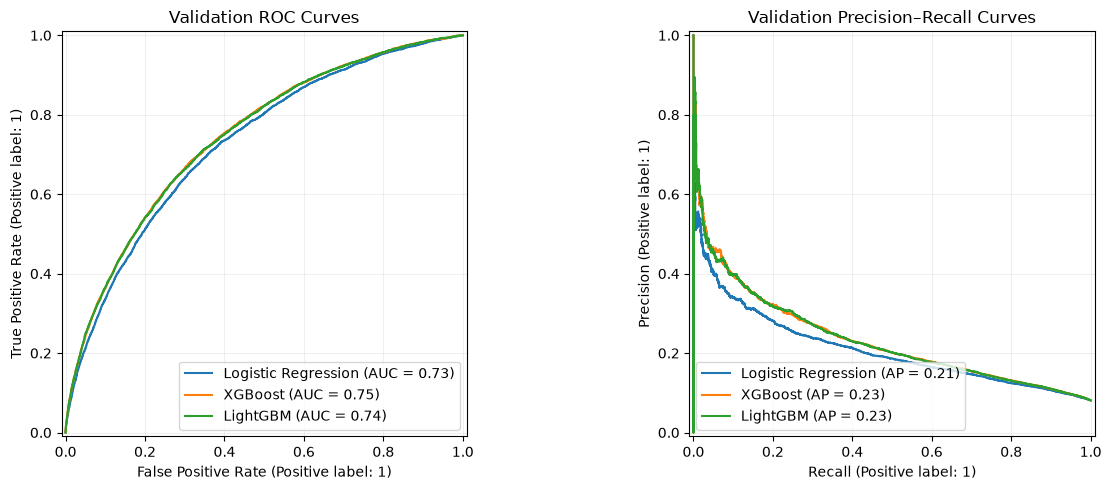

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, probabilities in validation_predictions.items():
    RocCurveDisplay.from_predictions(
        y_val, probabilities, name=name, ax=axes[0]
    )
    PrecisionRecallDisplay.from_predictions(
        y_val, probabilities, name=name, ax=axes[1]
    )
axes[0].set_title("Validation ROC Curves")
axes[1].set_title("Validation Precision–Recall Curves")
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Compare predicted probabilities and basic calibration
Inspect broad calibration patterns without using the reserved test set. A detailed calibration / stability / confidence-interval analysis belongs in Notebook 4.

**Caution:** This plot is for *diagnosis*. If you use validation results to tune/calibrate models, calibration must be fitted on separate data/folds—not evaluated on the same fitted calibration rows.

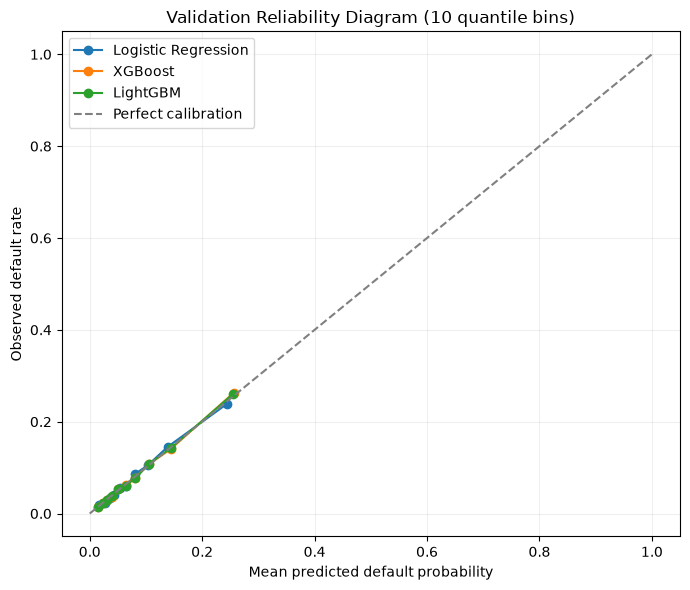

In [7]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(7, 6))
for name, probabilities in validation_predictions.items():
    observed, predicted = calibration_curve(
        y_val, probabilities, n_bins=10, strategy="quantile"
    )
    ax.plot(predicted, observed, marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax.set(xlabel="Mean predicted default probability", ylabel="Observed default rate",
       title="Validation Reliability Diagram (10 quantile bins)")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Save challenger artifacts and validation results
Save fitted models for future notebooks and the results for your README/model validation report. Test-set performance is **not** calculated here. The prediction table includes validation predictions only.

In [8]:
model_dir = ROOT / "models"
report_dir = ROOT / "reports"
model_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(challengers["XGBoost"], model_dir / "xgboost_challenger.joblib")
joblib.dump(challengers["LightGBM"], model_dir / "lightgbm_challenger.joblib")
comparison.to_csv(report_dir / "notebook3_validation_metrics.csv")

predictions = pd.DataFrame({
    "SK_ID_CURR": val["SK_ID_CURR"].to_numpy(),
    "TARGET": y_val.to_numpy(),
    "logistic_probability": validation_predictions["Logistic Regression"],
    "xgboost_probability": validation_predictions["XGBoost"],
    "lightgbm_probability": validation_predictions["LightGBM"],
})
predictions.to_csv(report_dir / "notebook3_validation_predictions.csv", index=False)

metadata = {
    "split": "stratified_random_60_20_20",
    "dataset": "Home Credit Default Risk / application_train.csv",
    "seed": SEED,
    "n_train": len(X_train),
    "n_validation": len(X_val),
    "features": features,
    "training_seconds": training_seconds,
    "metrics": metrics_by_model,
    "note": "All metrics are validation-only. No out-of-time or independent bank validation claimed.",
}
with (report_dir / "notebook3_metadata.json").open("w") as f:
    json.dump(metadata, f, indent=2)

print("Saved challenger models and validation reports.")
print("Models:", model_dir)
print("Reports:", report_dir)

Saved challenger models and validation reports.
Models: /Users/jeffery/Desktop/credit_risk/credit_risk/credit-risk-champion-challenger/models
Reports: /Users/jeffery/Desktop/credit_risk/credit_risk/credit-risk-champion-challenger/reports


## 9. Provisional champion–challenger decision

**Decision: advance XGBoost for deeper validation; do not promote it yet.** XGBoost has the strongest
validation ROC-AUC and average precision, with modestly better Brier score and KS than the incumbent.
The reliability diagram does not reveal a gross probability-quality tradeoff, but the improvement
must be quantified with a paired confidence interval because every model scored the same applicants.

The extra complexity is potentially justified, but only if XGBoost passes:

1. paired bootstrap uncertainty and pre-registered validation gates;
2. calibration and portfolio-segment review;
3. SHAP plausibility and protected-group outcome review;
4. drift/stress tests and operational monitoring design;
5. one-time locked-test evaluation after the criteria are frozen.

Logistic Regression therefore remains the champion and rollback model. Notebook 04 performs the
deeper statistical validation without opening the test set.